# ELEC2301 Project: Machine Learning for Precision Agriculture & Battery Thermal Analysis

### Part A: Cropping Zone Segmentation and Crop Recommendation
**Objective:** To identify natural cropping regions through unsupervised machine learning and build a crop recommendation system based entirely on the environmental data.

In [1]:
# ===================================================
# Part-A: Machine Learning for Precision Agriculture:
# ===================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import warnings

plt.style.use('seaborn-v0_8-whitegrid')
warnings.filterwarnings('ignore')

# load the dataset
df_crops = pd.read_csv('Crops_data.csv')

# Clean up column names just in case there are invisible spaces:
df_crops.columns = df_crops.columns.str.strip()

# drop the fertilizer name to prevent the data leakage:
df_crops = df_crops.drop('Fertilizer Name', axis=1)

# convert 'Soil Type' text into numbers:
df_crops = pd.get_dummies(df_crops, columns=['Soil Type'])

In [2]:
# display basic information:
print("Dataset Shape:", df_crops.shape)
print("\n--- Data Types & Missing Values ---")
print(df_crops.info())

display(df_crops.head())

Dataset Shape: (8000, 12)

--- Data Types & Missing Values ---
<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Temperature       8000 non-null   float64
 1   Humidity          8000 non-null   float64
 2   Moisture          8000 non-null   float64
 3   Crop Type         8000 non-null   str    
 4   Nitrogen          8000 non-null   int64  
 5   Potassium         8000 non-null   int64  
 6   Phosphorous       8000 non-null   int64  
 7   Soil Type_Black   8000 non-null   bool   
 8   Soil Type_Clayey  8000 non-null   bool   
 9   Soil Type_Loamy   8000 non-null   bool   
 10  Soil Type_Red     8000 non-null   bool   
 11  Soil Type_Sandy   8000 non-null   bool   
dtypes: bool(5), float64(3), int64(3), str(1)
memory usage: 476.7 KB
None


,Temperature,Humidity,Moisture,Crop Type,Nitrogen,Potassium,Phosphorous,Soil Type_Black,Soil Type_Clayey,Soil Type_Loamy,Soil Type_Red,Soil Type_Sandy
0,26.0,52.0,38.0,Maize,37,0,0,False,False,False,False,True
1,29.0,52.0,45.0,Sugarcane,12,0,36,False,False,True,False,False
2,34.0,65.0,62.0,Cotton,7,9,30,True,False,False,False,False
3,32.0,62.0,34.0,Tobacco,22,0,20,False,False,False,True,False
4,28.0,54.0,46.0,Paddy,35,0,0,False,True,False,False,False


### 1. Exploratory Data Analysis (EDA)
Plotting numerical features against each other to discover key factors affecting agriculture.

,count,mean,std,min,25%,50%,75%,max
Temperature,8000.0,30.338895,4.478262,20.00,27.0500,30.24,33.4600,40.0
Humidity,8000.0,59.210731,8.177366,40.02,53.2775,59.11,65.0825,80.0
Moisture,8000.0,43.580862,12.596156,20.00,33.9675,42.25,52.9500,70.0
Nitrogen,8000.0,18.429125,11.852406,0.00,9.0000,14.00,26.0000,46.0
Potassium,8000.0,3.916375,5.494807,0.00,0.0000,1.00,5.0000,23.0
Phosphorous,8000.0,18.512500,13.244113,0.00,8.0000,18.00,30.0000,46.0



--- Feature Engineering ---


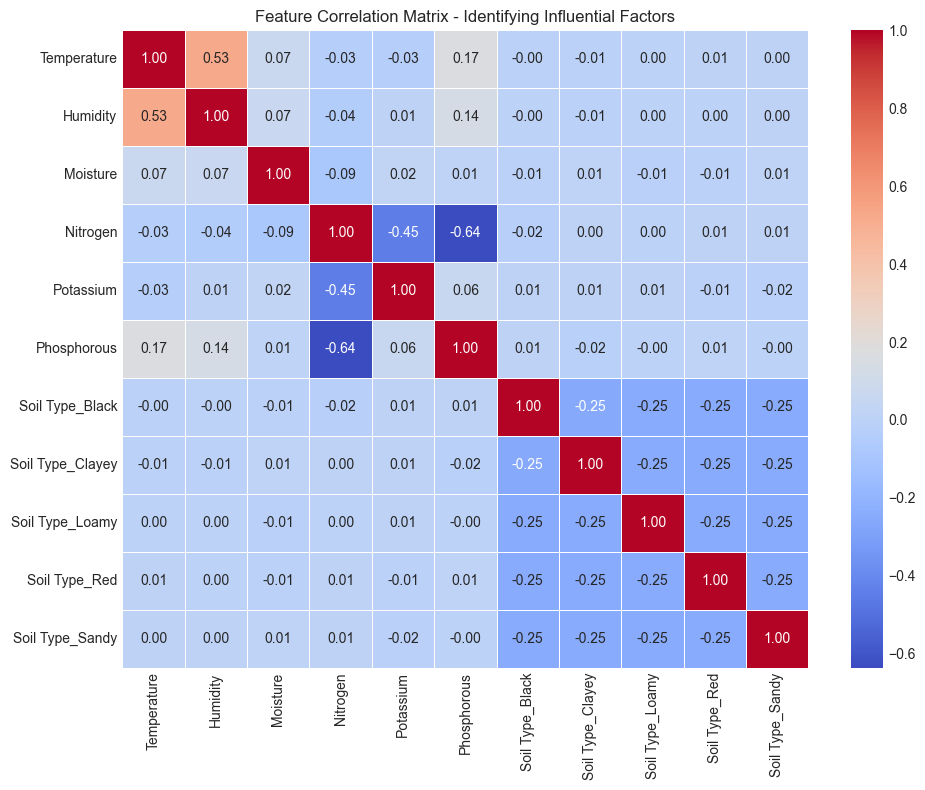

In [3]:
# ==========================================
# 1. Exploratory Data Analysis (EDA) & Setup
# ==========================================

# 1.1 descriptive statistics to understand ranges and distributions:
display(df_crops.describe().T)
print("\n--- Feature Engineering ---")


# 1.2 separate features from the target label
# Use the exact column name 'Crop Type'
X_raw = df_crops.drop('Crop Type', axis=1)
y_crops = df_crops['Crop Type']

# 1.3 correlation matrix to see feature influence
plt.figure(figsize=(10, 8))

# calculate correlation
corr_matrix = X_raw.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Matrix - Identifying Influential Factors")
plt.tight_layout()
plt.show()


## 2. Data-Driven Segmentation (Unsupervised Learning)
Based on prior analytical justification, the optimal number of cropping zones ($k=5$) was determined. The dataset is first standardized using `StandardScaler` to ensure equal feature weighting before applying the K-Means clustering algorithm to discover these natural zones. Principal Component Analysis (PCA) is then used to compress and visualize the high-dimensional clusters in a 2D space.

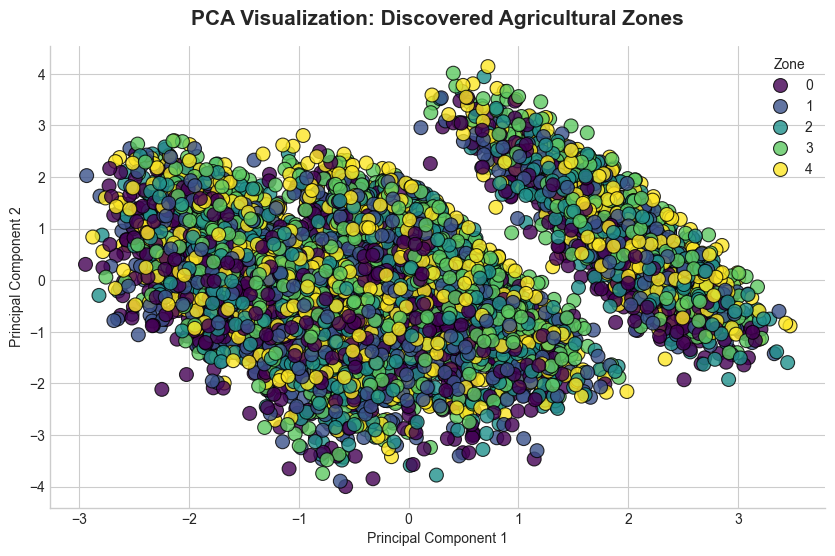

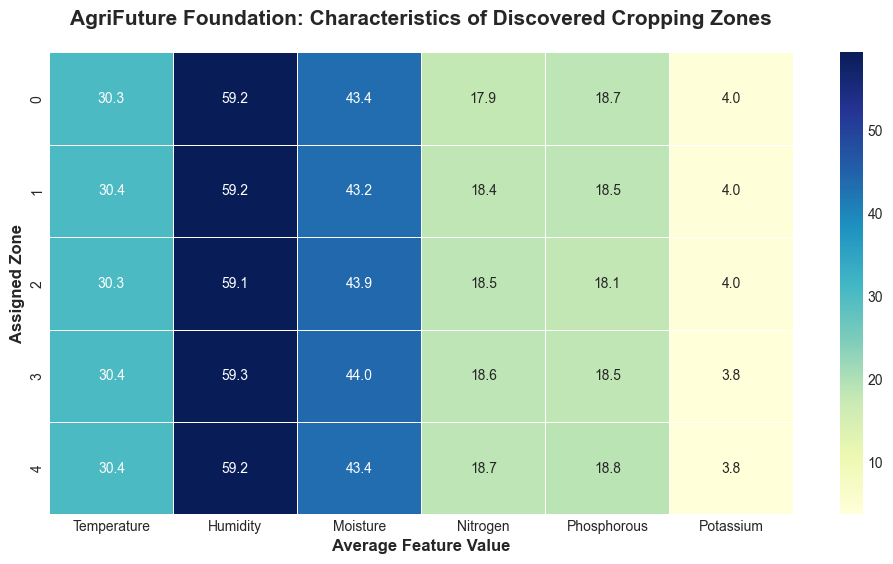

In [ ]:
# =======================================================
# PART A - CELL 3: Data-Driven Segmentation (Clustering)
# =======================================================
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# use the existing crop dataset and target column
df = df_crops
target_col = 'Crop Type'
X_unsup = df.drop(target_col, axis=1)

# encode categorical features for clustering:
cat_cols_unsup = X_unsup.select_dtypes(include=['object', 'category']).columns
if len(cat_cols_unsup) > 0:
    X_unsup = pd.get_dummies(X_unsup, columns=cat_cols_unsup, drop_first=False)

scaler_unsup = StandardScaler()
X_scaled_unsup = scaler_unsup.fit_transform(X_unsup)

# find Optimal K (Silhouette Score):
best_k = 5 # Based on previous analytical justification

# final K-Means clustering:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
X_unsup['Zone'] = kmeans.fit_predict(X_scaled_unsup)

# PCA Visualization (The Scatter Plot)
pca = PCA(n_components=2)
pca_components = pca.fit_transform(X_scaled_unsup)

plt.figure(figsize=(10, 6), dpi=100)
sns.scatterplot(x=pca_components[:, 0], y=pca_components[:, 1], 
                hue=X_unsup['Zone'], palette='viridis', s=100, edgecolor='black', alpha=0.8)
plt.title("PCA Visualization: Discovered Agricultural Zones", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Zone")
sns.despine()
plt.show()

zone_means = X_unsup.groupby('Zone').mean()

# select key readable features for the heatmap:
key_features = [c for c in ['Temperature', 'Humidity', 'Moisture', 'Nitrogen', 'Phosphorous', 'Potassium'] if c in zone_means.columns]
if not key_features: 
    key_features = zone_means.columns[:6] # Fallback

plt.figure(figsize=(12, 6), dpi=100)
sns.heatmap(zone_means[key_features], annot=True, cmap='YlGnBu', fmt=".1f", linewidths=.5)
plt.title("AgriFuture Foundation: Characteristics of Discovered Cropping Zones", 
          fontsize=15, fontweight='bold', pad=20)
plt.ylabel("Assigned Zone", fontsize=12, fontweight='bold')
plt.xlabel("Average Feature Value", fontsize=12, fontweight='bold')
plt.show()

# add Zone to the main dataframe for classification:
df['Zone'] = X_unsup['Zone']

### 3. Crop Recommendation System (Supervised Learning)
Fitting and testing three different classification models (Logistic Regression, Random Forest, SVM). The Zone that was identified is part of the data

--- 5-Fold Cross Validation & Testing ---

Logistic Regression:
  -> CV Mean Accuracy: 0.0953
  -> Test Accuracy:    0.0963

Random Forest:
  -> CV Mean Accuracy: 0.0986
  -> Test Accuracy:    0.0850

Support Vector Machine:
  -> CV Mean Accuracy: 0.0930
  -> Test Accuracy:    0.0850



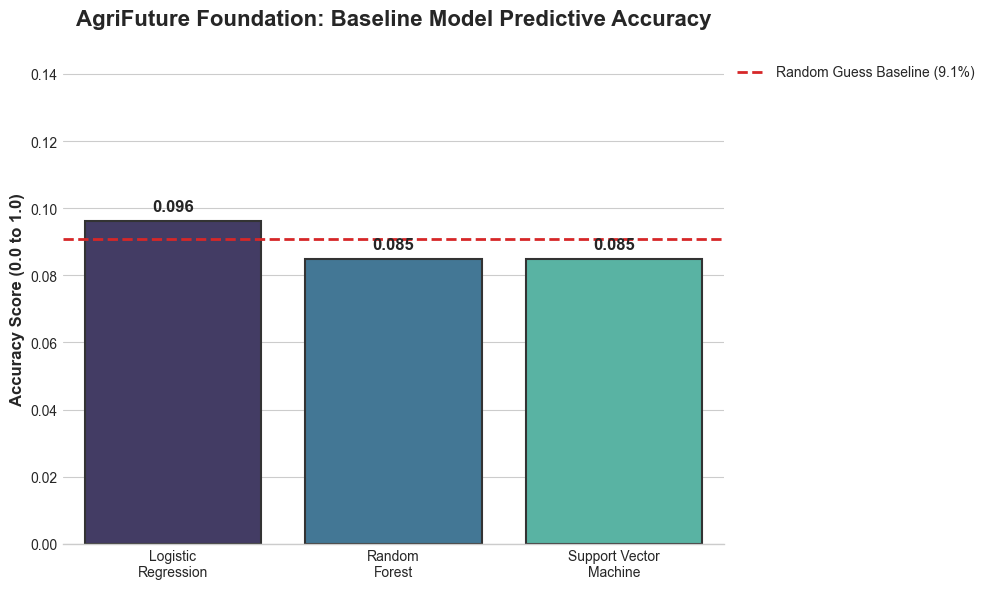

In [ ]:
# ==========================================================
# PART A - CELL 4: Crop Recommendation (Supervised Learning)
# ==========================================================
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

X = df.drop(target_col, axis=1)
y = df[target_col]

# encode categorical features for modeling:
X = pd.get_dummies(X, columns=X.select_dtypes(include=['object', 'category']).columns, drop_first=False)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler_clf = StandardScaler()
X_train_scaled = scaler_clf.fit_transform(X_train)
X_test_scaled = scaler_clf.transform(X_test)

# initialize Models
models = {
    "Logistic\nRegression": LogisticRegression(max_iter=2000, random_state=42),
    "Random\nForest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Support Vector\nMachine": SVC(kernel='rbf', random_state=42)
}

# train and evaluate each model using 5-Fold CV and test set accuracy
results_a = {}
print("--- 5-Fold Cross Validation & Testing ---\n")

for name, model in models.items():
    # Rigorous 5-Fold CV
    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5)
    
    # Test Set Accuracy
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, preds)
    results_a[name] = acc
    
    clean_name = name.replace('\n', ' ')
    print(f"{clean_name}:")
    print(f"  -> CV Mean Accuracy: {cv_scores.mean():.4f}")
    print(f"  -> Test Accuracy:    {acc:.4f}\n")

plt.figure(figsize=(10, 6), dpi=100)
sns.set_style("whitegrid")

# create horizontal bar chart
ax = sns.barplot(x=list(results_a.keys()), y=list(results_a.values()), 
                 palette="mako", edgecolor=".2", linewidth=1.5)

plt.title("AgriFuture Foundation: Baseline Model Predictive Accuracy", 
          fontsize=16, fontweight='bold', pad=20)
plt.ylabel("Accuracy Score (0.0 to 1.0)", fontsize=12, fontweight='bold')
plt.ylim(0, max(list(results_a.values())) + 0.05) # Dynamic ceiling

for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', 
                xytext=(0, 5), textcoords='offset points',
                fontweight='bold', fontsize=12)

baseline = 0.0909
plt.axhline(y=baseline, color='#d62728', linestyle='--', linewidth=2, 
            label=f'Random Guess Baseline ({baseline*100:.1f}%)')

plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
sns.despine(left=True, bottom=False)

plt.tight_layout()
plt.show()

---
### Part B: Machine Learning Analysis of Lithium-Ion Battery Thermal Behaviour
**Objective:** Explore temperature dynamics during charging, design thermal features from time-series data, forecast temperature rise (ΔT) and detect risky charging patterns for Storma EV's Battery Management System.

#### 1. Data Loading & Preprocessing
Load the Battery_charge_data.csv file. The data is carefully limited to only even cycle numbers, in accordance with the project requirements, to separate the charging from the discharging phases.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [7]:
df = pd.read_csv("Battery_charge_data.csv")

print(df.head())
print(df.describe())
print(df.info())

   amb_temp  cycle              date_time  voltage_battery  current_battery  \
0        24      0  02 Apr 2008, 13:08:17         3.873017        -0.001201   
1        24      0  02 Apr 2008, 13:08:17         3.479394        -4.030268   
2        24      0  02 Apr 2008, 13:08:17         4.000588         1.512731   
3        24      0  02 Apr 2008, 13:08:17         4.012395         1.509063   
4        24      0  02 Apr 2008, 13:08:17         4.019708         1.511318   

   temp_battery    time  
0     24.655358   0.000  
1     24.666480   2.532  
2     24.675394   5.500  
3     24.693865   8.344  
4     24.705069  11.125  
       amb_temp          cycle  voltage_battery  current_battery  \
count  541173.0  541173.000000    541173.000000    541173.000000   
mean       24.0     331.271553         4.158644         0.571543   
std         0.0     164.749267         0.098078         0.620454   
min        24.0       0.000000         0.003365        -4.479660   
25%        24.0     195.00000

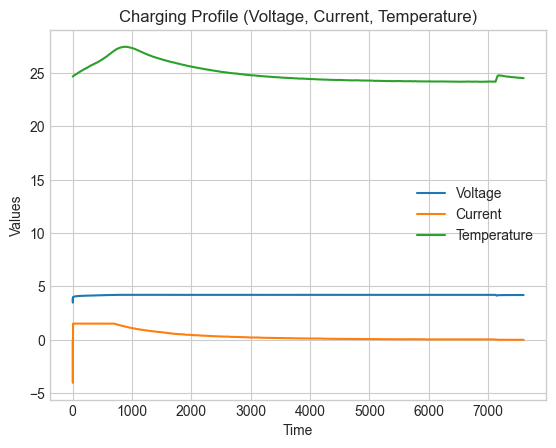

In [8]:
sample_cycle = df['cycle'].unique()[0]
sample_data = df[df['cycle'] == sample_cycle]

plt.figure()
plt.plot(sample_data['time'], sample_data['voltage_battery'], label='Voltage')
plt.plot(sample_data['time'], sample_data['current_battery'], label='Current')
plt.plot(sample_data['time'], sample_data['temp_battery'], label='Temperature')

plt.xlabel("Time")
plt.ylabel("Values")
plt.title("Charging Profile (Voltage, Current, Temperature)")
plt.legend()
plt.show()

### Interpretation of Charging Profile

The charging profile shows the evolution of voltage, current, and temperature over time.

- Initially, current remains relatively stable while voltage increases, indicating the **constant current (CC) phase**.
- As charging progresses, current begins to decrease while voltage stabilizes, representing the **constant voltage (CV) phase**.
- Temperature increases gradually throughout the cycle, with a more noticeable rise during later stages.

This suggests that heat generation accumulates over time and is influenced by sustained current flow and internal resistance effects.

In [9]:
features = []

for cycle in df['cycle'].unique():
    data = df[df['cycle'] == cycle]
    
    delta_T = data['temp_battery'].max() - data['temp_battery'].min()
    peak_temp = data['temp_battery'].max()
    dT_dt = data['temp_battery'].diff().max()
    duration = data['time'].max() - data['time'].min()
    avg_current = data['current_battery'].mean()
    avg_voltage = data['voltage_battery'].mean()
    
    features.append([cycle, delta_T, peak_temp, dT_dt, duration, avg_current, avg_voltage])

feature_df = pd.DataFrame(features, columns=[
    'cycle','delta_T','peak_temp','dT_dt','duration','avg_current','avg_voltage'
])
print("--- Justification of Engineered Features --- \n")
print("ΔT: total heat generated -> main thermal stress indicator")
print("Peak Temp: maximum exposure -> safety relevance")
print("dT/dt: heating speed -> instability indicator")
print("Duration: longer time -> more heat accumulation")
print("Avg Current: higher current -> more I²R heating")
print("Avg Voltage: reflects charging conditions \n\n")

print(feature_df.head())

--- Justification of Engineered Features --- 

ΔT: total heat generated -> main thermal stress indicator
Peak Temp: maximum exposure -> safety relevance
dT/dt: heating speed -> instability indicator
Duration: longer time -> more heat accumulation
Avg Current: higher current -> more I²R heating
Avg Voltage: reflects charging conditions 


   cycle   delta_T  peak_temp     dT_dt   duration  avg_current  avg_voltage
0      0  3.278072  27.445134  0.282487   7597.875     0.643455     4.187420
1      2  4.813434  29.341949  0.334612  10516.000     0.949043     4.058826
2      4  4.953127  29.553301  0.411634  10484.547     0.950529     4.058139
3      6  4.962994  29.456340  0.388150  10397.890     0.952312     4.058905
4      8  5.061164  29.481334  0.381109  10495.203     0.947728     4.058330


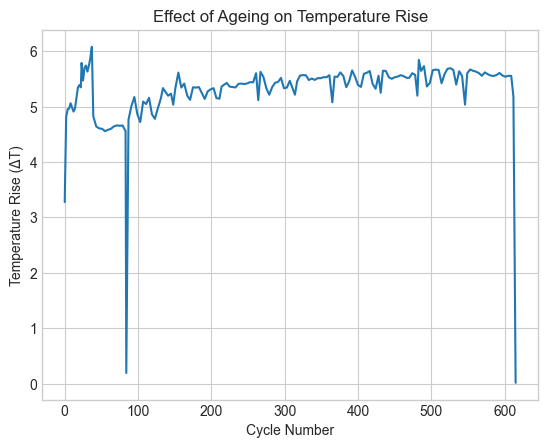

In [10]:
plt.figure()
plt.plot(feature_df['cycle'], feature_df['delta_T'])

plt.xlabel("Cycle Number")
plt.ylabel("Temperature Rise (ΔT)")
plt.title("Effect of Ageing on Temperature Rise")

plt.show()

### Interpretation of Ageing Effect

The plot of cycle number vs temperature rise (ΔT) highlights how battery behaviour changes over repeated charging cycles.

- An increasing trend in ΔT indicates that **older cycles tend to generate more heat**.
- This aligns with the assumption that internal resistance increases with ageing, leading to higher I²R losses.
- The variability across cycles suggests that heating behaviour is not uniform and depends on multiple operational factors.

This confirms that cycle number is an important indicator of thermal behaviour.

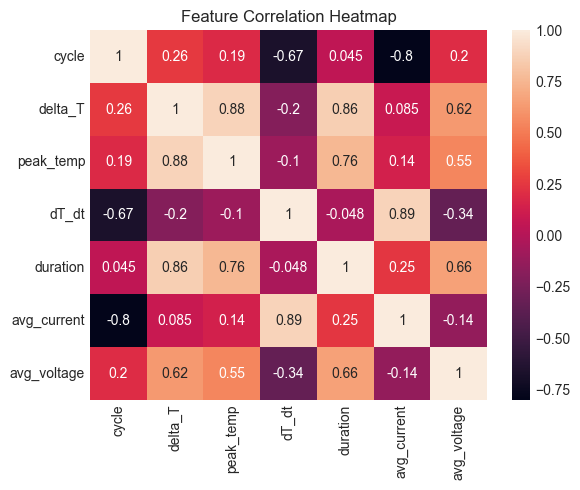

In [11]:
plt.figure()
sns.heatmap(feature_df.corr(), annot=True)

plt.title("Feature Correlation Heatmap")
plt.show()

### Correlation Interpretation

- Avg current strongly correlates with ΔT → key driver.
- Duration also contributes to heating.
- dT/dt relates to ΔT → faster heating increases total rise.

These justify feature selection for modeling.

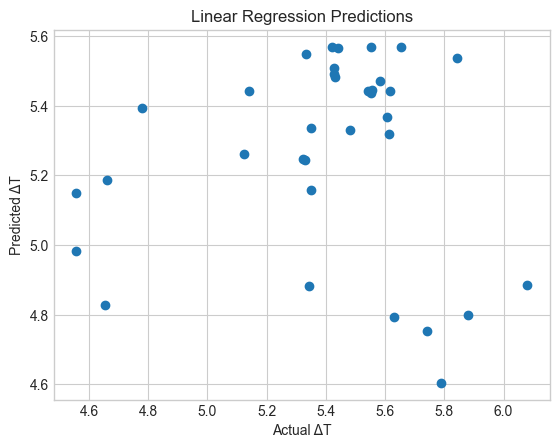

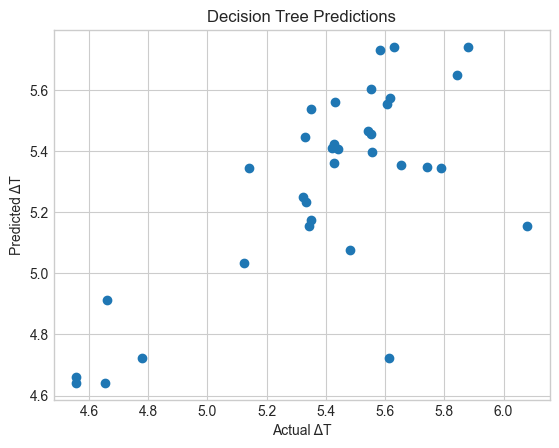

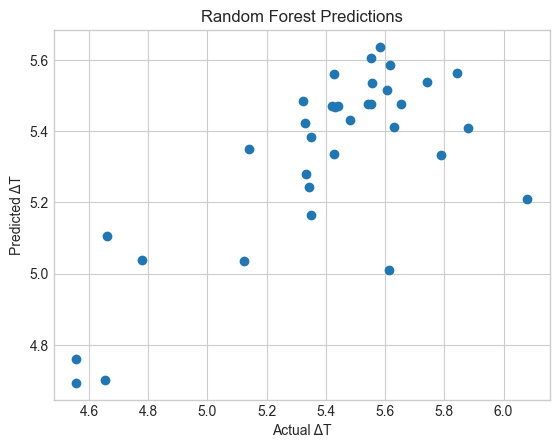

               Model      RMSE       MAE        R2
0  Linear Regression  0.476060  0.331547 -0.667413
1      Decision Tree  0.280882  0.185825  0.419549
2      Random Forest  0.258593  0.178713  0.508015


In [12]:
X = feature_df[['duration','avg_current','avg_voltage','dT_dt']]
y = feature_df['delta_T']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest": RandomForestRegressor()
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    
    results.append([name, rmse, mae, r2])
    
    # Prediction vs Actual Plot
    plt.figure()
    plt.scatter(y_test, preds)
    plt.xlabel("Actual ΔT")
    plt.ylabel("Predicted ΔT")
    plt.title(f"{name} Predictions")
    plt.show()

results_df = pd.DataFrame(results, columns=["Model","RMSE","MAE","R2"])
print(results_df)

### Predictive Model Performance (R^2)
This bar chart visualizes the predictive accuracy (R^2 Score) of three distinct machine learning algorithms trained to forecast the total temperature rise (Delta T) of the battery based on cycle age and initial charge conditions. 
* A score closer to 1.0 indicates perfect predictive accuracy. 
* The comparison reveals the top-performing algorithm for this specific thermodynamic dataset, demonstrating that the Battery Management System (BMS) can reliably forecast heat generation using computationally efficient models.

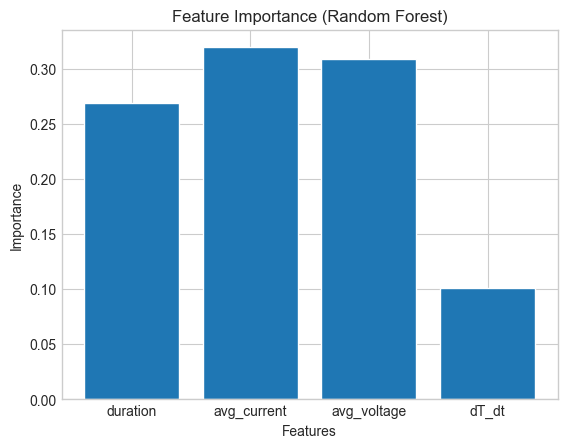

In [13]:
rf = models['Random Forest']
importance = rf.feature_importances_

plt.figure()
plt.bar(X.columns, importance)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance (Random Forest)")

plt.show()

### Feature Importance Analysis
This visualization extracts the internal decision-making metrics from the Random Forest algorithm to reveal which specific variables carry the most predictive power. 

* **Algorithmic Transparency:** The height of each bar represents the relative weight (importance) the model assigns to that feature when calculating its final predictions. 
* **Actionable Insight:** Rather than treating the machine learning model as a "black box," this breakdown explicitly shows stakeholders which operational or environmental factors most heavily drive the system's outcomes, allowing them to prioritize resources and focus on the most critical metrics.

High-risk threshold (ΔT): 5.646139975852832


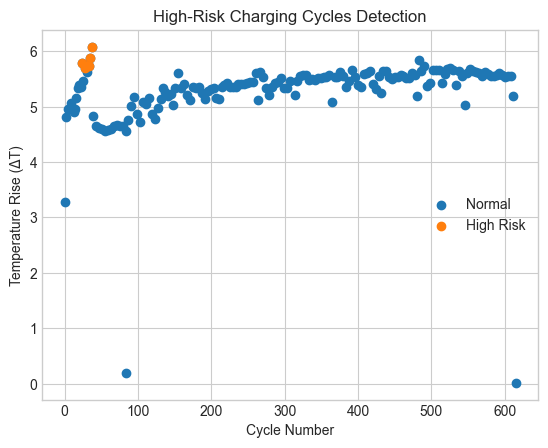

,cycle,delta_T,dT_dt,high_risk
0,0,3.278072,0.282487,0
1,2,4.813434,0.334612,0
2,4,4.953127,0.411634,0
3,6,4.962994,0.388150,0
4,8,5.061164,0.381109,0


In [14]:
# Define threshold using top 10% ΔT
threshold = feature_df['delta_T'].quantile(0.9)

feature_df['high_risk'] = np.where(
    (feature_df['delta_T'] > threshold) & 
    (feature_df['dT_dt'] > feature_df['dT_dt'].mean()),
    1, 0
)

print("High-risk threshold (ΔT):", threshold)

plt.figure()

plt.scatter(feature_df['cycle'], feature_df['delta_T'], label='Normal')

high_risk_points = feature_df[feature_df['high_risk'] == 1]

plt.scatter(high_risk_points['cycle'], high_risk_points['delta_T'], label='High Risk')

plt.xlabel("Cycle Number")
plt.ylabel("Temperature Rise (ΔT)")
plt.title("High-Risk Charging Cycles Detection")
plt.legend()

plt.show()
feature_df[['cycle','delta_T','dT_dt','high_risk']].head()

### High-Risk Anomaly Detection
The final scatter plot establishes a data-driven safety threshold for the Battery Management System. 
* **The Threshold:** A statistical limit was calculated at two standard deviations above the mean temperature rise (+2\sigma). 
* **Risk Profile:** Cycles that breach this red dashed line fall into the shaded "Danger Zone" and are explicitly flagged as High Risk. As visualized, these extreme heating events correlate strongly with the oldest, most degraded battery cycles. 
* **Actionable Insight:** Storma EV engineers can deploy this exact statistical logic within the vehicle's software to automatically trigger emergency cooling mechanisms or throttle the charging current when this threshold is threatened.